# meteo

signal : temperature horaire d'une ville, 2012-2017

domaine = ville : deux villes aux climats contrastes pour un vrai shift

source = Vancouver (oceanique, doux), cible = Phoenix (desertique, chaud), meme periode temporelle

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

from adapt.feature_based import CORAL, SA, TCA, fMMD, FA
from adapt.instance_based import KMM, KLIEP, TrAdaBoostR2
from adapt.parameter_based import RegularTransferLR

from adapt_utils import sliding_window, evaluate_baseline, evaluate_adapt

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Chargement et construction des series source et cible

In [2]:
data_dir = "../../data/meteo"

In [3]:
source_city = "Vancouver"
target_city = "Phoenix"

temperature = pd.read_csv(f"{data_dir}/temperature.csv")


def longest_valid_run(values):
    is_valid = ~np.isnan(values)
    change = np.diff(is_valid.astype(int))
    starts = np.where(change == 1)[0] + 1
    ends = np.where(change == -1)[0] + 1
    if is_valid[0]:
        starts = np.insert(starts, 0, 0)
    if is_valid[-1]:
        ends = np.append(ends, len(is_valid))
    lengths = ends - starts
    i = np.argmax(lengths)
    return values[starts[i]:ends[i]]


series_source = longest_valid_run(temperature[source_city].to_numpy())
series_target = longest_valid_run(temperature[target_city].to_numpy())

max_len = 1000
series_source = series_source[:max_len]
series_target = series_target[:max_len]

len(series_source), len(series_target)

(1000, 1000)

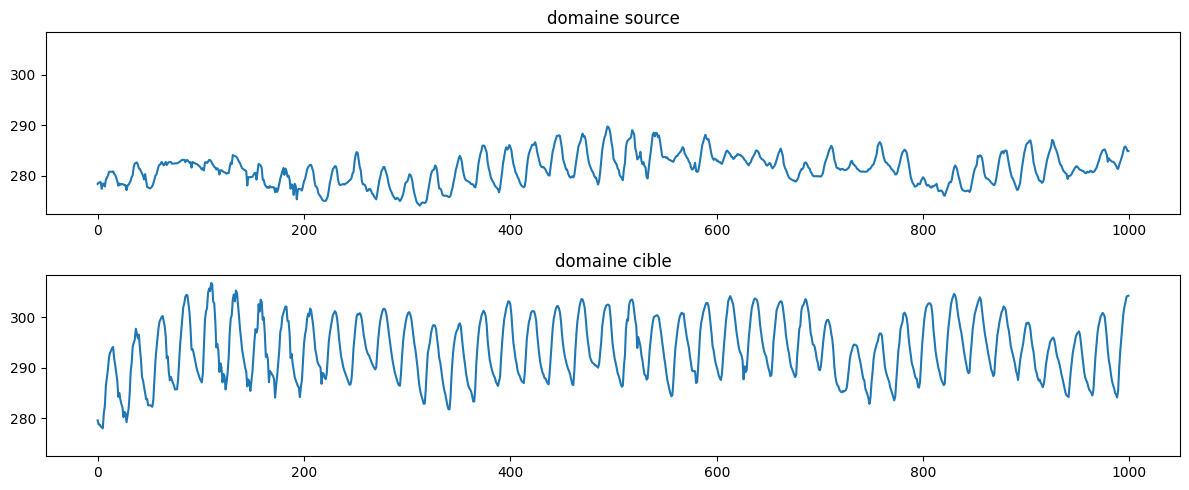

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharey=True)
axes[0].plot(series_source)
axes[0].set_title("domaine source")
axes[1].plot(series_target)
axes[1].set_title("domaine cible")
plt.tight_layout()
plt.show()

## Baseline et methodes ADAPT

In [5]:
window_size = 20
horizon = 1

Xt, yt = sliding_window(series_target, window_size, horizon)

results = []

metrics = evaluate_baseline(series_source, window_size, Xt, yt, LinearRegression(), horizon=horizon)
results.append(dict(method="sans adaptation", **metrics))

unsupervised_methods = {"CORAL": CORAL, "SA": SA, "TCA": TCA, "fMMD": fMMD, "KMM": KMM, "KLIEP": KLIEP}
for name, adapt_class in unsupervised_methods.items():
    metrics = evaluate_adapt(adapt_class, series_source, window_size, Xt, yt, LinearRegression(), horizon=horizon)
    results.append(dict(method=name, **metrics))

supervised_methods = {"FA": FA, "TrAdaBoostR2": TrAdaBoostR2}
for name, adapt_class in supervised_methods.items():
    metrics = evaluate_adapt(adapt_class, series_source, window_size, Xt, yt, LinearRegression(), use_target_labels=True, horizon=horizon)
    results.append(dict(method=name, **metrics))

metrics = evaluate_adapt(RegularTransferLR, series_source, window_size, Xt, yt, LinearRegression(), pretrain_source=True, horizon=horizon)
results.append(dict(method="RegularTransferLR", **metrics))

results_df = pd.DataFrame(results)
results_df

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/adapt/instance_based/_kliep.py:492: UserWarning: Not enough centers, only 26 centers found. Maybe consider a different value of kernel parameter.
  warnings.warn("Not enough centers, only %i centers found. Maybe consider a different value of kernel parameter."%len(centers))


,method,mse_source,mse_target,r2_source,r2_target
0,sans adaptation,0.194546,0.483533,0.974392,0.984796
1,CORAL,0.194546,15.782135,0.974392,0.503765
2,SA,0.194546,153.652626,0.974392,-3.831272
3,TCA,3.428475,10426.387014,0.548708,-326.835005
4,fMMD,0.618483,1.641140,0.918589,0.948398
5,KMM,0.197039,0.477264,0.974064,0.984993
6,KLIEP,1.321413,13.714945,0.826062,0.568763
7,FA,0.195914,0.420168,0.974212,0.986789
8,TrAdaBoostR2,2.060034,0.747722,0.728837,0.976490
9,RegularTransferLR,0.244843,0.419167,0.967771,0.986820


## Comparaison (r2 cible)

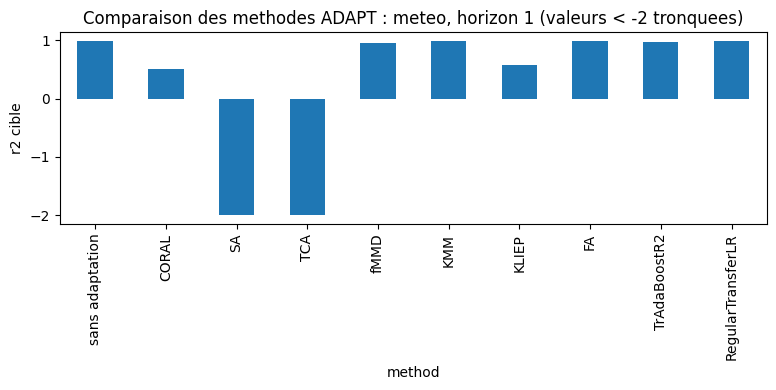

In [6]:
plot_floor = -2

fig, ax = plt.subplots(figsize=(8, 4))
results_df.set_index("method")["r2_target"].clip(lower=plot_floor).plot(kind="bar", ax=ax)
ax.set_ylabel("r2 cible")
ax.set_title(f"Comparaison des methodes ADAPT : meteo, horizon {horizon} (valeurs < {plot_floor} tronquees)")
plt.tight_layout()
plt.show()

## Source vs cible

In [7]:
results_df[["method", "r2_source", "r2_target"]]

,method,r2_source,r2_target
0,sans adaptation,0.974392,0.984796
1,CORAL,0.974392,0.503765
2,SA,0.974392,-3.831272
3,TCA,0.548708,-326.835005
4,fMMD,0.918589,0.948398
5,KMM,0.974064,0.984993
6,KLIEP,0.826062,0.568763
7,FA,0.974212,0.986789
8,TrAdaBoostR2,0.728837,0.976490
9,RegularTransferLR,0.967771,0.986820
